## 1. Install dependencies (Colab)

Colab already has torch / pandas / numpy / scipy / matplotlib. Only `yfinance` usually needs installing.

In [1]:
!pip install -q yfinance

## 2. Imports

In [2]:
import os, json, random, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

print("torch", torch.__version__, "| cuda available:", torch.cuda.is_available())


torch 2.10.0+cu128 | cuda available: True


## 3. Config

In [3]:
UNIVERSE = [
    # Mega-cap tech
    "AAPL","MSFT","NVDA","AMZN","META","GOOGL","GOOG","TSLA","AVGO","ORCL",
    "CRM","ADBE","AMD","INTC","QCOM","CSCO","TXN","IBM","NOW","INTU",
    # Financials
    "JPM","BAC","WFC","C","GS","MS","BLK","SCHW","AXP","USB",
    # Healthcare
    "UNH","JNJ","LLY","PFE","ABBV","TMO","MRK","ABT","DHR","BMY",
    # Consumer
    "WMT","COST","HD","LOW","TGT","MCD","SBUX","NKE","KO","PEP",
    # Industrial / Energy / Materials
    "CAT","DE","BA","HON","UPS","XOM","CVX","COP","LIN","APD",
    # Comm / Media
    "DIS","NFLX","CMCSA","T","VZ",
]

START_DATE = "2010-01-01"
END_DATE   = "2025-12-31"
TRAIN_END  = "2020-12-31"
VALID_END  = "2022-12-31"

FORWARD_DAYS = 5
HOLD_DAYS    = 5
TOP_Q        = 0.20
BOTTOM_Q     = 0.20

SEEDS        = [11, 22, 33, 44, 55]
MAX_EPOCHS   = 40
BATCH_SIZE   = 2048
HIDDEN_SIZES = (128, 64, 32)
DROPOUT      = 0.30
WEIGHT_DECAY = 1e-4
LR           = 1e-3
PATIENCE     = 6

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
OUTPUT_DIR = "mlp_alpha_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)


## 4. Download prices

In [4]:
def download_prices(tickers, start, end):
    print(f"Downloading {len(tickers)} tickers from {start} to {end} ...")
    df = yf.download(
        tickers=tickers, start=start, end=end,
        auto_adjust=True, progress=False,
        group_by="ticker", threads=True,
    )
    frames = []
    for t in tickers:
        if t not in df.columns.get_level_values(0):
            continue
        sub = df[t].copy()
        if sub.dropna(how="all").empty:
            continue
        sub.columns = [c.lower() for c in sub.columns]
        sub["ticker"] = t
        sub = sub.reset_index().rename(columns={"Date": "date"})
        frames.append(sub[["date","ticker","open","high","low","close","volume"]])
    out = pd.concat(frames, ignore_index=True)
    out["date"] = pd.to_datetime(out["date"])
    out = out.dropna(subset=["close"]).sort_values(["ticker","date"]).reset_index(drop=True)
    return out

prices = download_prices(UNIVERSE, START_DATE, END_DATE)
print(f"Got {prices['ticker'].nunique()} tickers, {len(prices):,} rows")
prices.head()


Got 65 tickers, 259,392 rows


,date,ticker,open,high,low,close,volume
0,2010-01-04,AAPL,6.395004,6.427064,6.363543,6.412383,493729600.0
1,2010-01-05,AAPL,6.430062,6.459725,6.389611,6.423470,601904800.0
2,2010-01-06,AAPL,6.423470,6.448939,6.314705,6.321297,552160000.0
3,2010-01-07,AAPL,6.344668,6.352159,6.263768,6.309611,477131200.0
4,2010-01-08,AAPL,6.301222,6.352159,6.264068,6.351560,447610800.0


## 5. Feature engineering (per ticker, time-series)

Momentum over multiple horizons, vol-normalized momentum, moving-average ratios, 52-week distance, RSI, candle structure, volume ratios.

In [5]:
def compute_rsi(series, window=14):
    delta = series.diff()
    gain = delta.clip(lower=0); loss = -delta.clip(upper=0)
    ag = gain.rolling(window).mean(); al = loss.rolling(window).mean()
    rs = ag / (al + 1e-12)
    return 100 - 100/(1+rs)

def make_features(data, forward_days=5):
    df = data.copy()
    g = df.groupby("ticker")

    # multi-horizon returns (momentum + reversal)
    for n in [1,2,3,5,10,21,63,126]:
        df[f"ret_{n}d"] = g["close"].pct_change(n)
    df["reversal_1d"] = -df["ret_1d"]
    df["reversal_5d"] = -df["ret_5d"]

    # vol & vol-of-vol
    df["vol_21d"] = g["ret_1d"].transform(lambda x: x.rolling(21).std())
    df["vol_63d"] = g["ret_1d"].transform(lambda x: x.rolling(63).std())
    df["vov_21"]  = df.groupby("ticker")["vol_21d"].transform(lambda x: x.rolling(21).std())

    # vol-normalized momentum (rolling Sharpe-like)
    df["momo_21_vol"]  = df["ret_21d"]  / (df["vol_21d"]*np.sqrt(21)  + 1e-8)
    df["momo_63_vol"]  = df["ret_63d"]  / (df["vol_63d"]*np.sqrt(63)  + 1e-8)
    df["momo_126_vol"] = df["ret_126d"] / (df["vol_63d"]*np.sqrt(126) + 1e-8)

    # moving average ratios
    for n in [5,10,21,63,126]:
        df[f"ma_{n}"] = g["close"].transform(lambda x, n=n: x.rolling(n).mean())
        df[f"p_to_ma{n}"] = df["close"] / df[f"ma_{n}"] - 1
    df["ma5_to_21"]   = df["ma_5"]  / df["ma_21"]  - 1
    df["ma21_to_63"]  = df["ma_21"] / df["ma_63"]  - 1
    df["ma63_to_126"] = df["ma_63"] / df["ma_126"] - 1

    # 52w distance
    df["hi_252"] = g["close"].transform(lambda x: x.rolling(252).max())
    df["lo_252"] = g["close"].transform(lambda x: x.rolling(252).min())
    df["dist_hi_252"] = df["close"] / df["hi_252"] - 1
    df["dist_lo_252"] = df["close"] / df["lo_252"] - 1

    # RSI
    df["rsi_14"] = g["close"].transform(lambda x: compute_rsi(x, 14))
    df["rsi_5"]  = g["close"].transform(lambda x: compute_rsi(x, 5))

    # candle / intraday structure
    df["hl_spread"]  = (df["high"] - df["low"])  / (df["close"] + 1e-12)
    df["oc_spread"]  = (df["close"] - df["open"]) / (df["open"]  + 1e-12)
    df["upper_wick"] = (df["high"] - df[["open","close"]].max(axis=1)) / (df["close"]+1e-12)
    df["lower_wick"] = (df[["open","close"]].min(axis=1) - df["low"]) / (df["close"]+1e-12)

    # volume
    for n in [5,21,63]:
        df[f"vol_ma_{n}"]    = g["volume"].transform(lambda x, n=n: x.rolling(n).mean())
        df[f"vol_ratio_{n}"] = df["volume"] / (df[f"vol_ma_{n}"] + 1e-8)

    # forward return (target base)
    df["fwd_ret"] = g["close"].shift(-forward_days) / df["close"] - 1
    return df

print("Engineering features...")
feat = make_features(prices, forward_days=FORWARD_DAYS)
feat.tail()


Engineering features...


,date,ticker,open,high,low,close,volume,ret_1d,ret_2d,ret_3d,...,oc_spread,upper_wick,lower_wick,vol_ma_5,vol_ratio_5,vol_ma_21,vol_ratio_21,vol_ma_63,vol_ratio_63,fwd_ret
259387,2025-12-23,XOM,117.685581,119.235249,117.536573,118.629288,12567600.0,0.010749,0.023395,0.024712,...,0.008019,0.005108,0.001256,20391360.0,0.616320,1.644692e+07,0.764131,1.480837e+07,0.848682,NaN
259388,2025-12-24,XOM,118.539891,119.255124,118.331282,118.430618,6137400.0,-0.001675,0.009056,0.021681,...,-0.000922,0.006039,0.000839,17918400.0,0.342519,1.588037e+07,0.386477,1.466749e+07,0.418435,NaN
259389,2025-12-26,XOM,118.102798,118.758432,117.745181,118.321342,8066100.0,-0.000923,-0.002596,0.008125,...,0.001850,0.003694,0.003022,16790500.0,0.480397,1.557711e+07,0.517818,1.450078e+07,0.556253,NaN
259390,2025-12-29,XOM,119.354460,120.496847,118.609426,119.731941,14782500.0,0.011922,0.010988,0.009295,...,0.003163,0.006388,0.006223,10664440.0,1.386149,1.572625e+07,0.939989,1.443083e+07,1.024369,NaN
259391,2025-12-30,XOM,120.298168,120.993538,119.831279,120.188896,11150500.0,0.003816,0.015784,0.014846,...,-0.000908,0.005786,0.002975,10540820.0,1.057840,1.591242e+07,0.700742,1.432090e+07,0.778617,NaN


## 6. Cross-sectional processing

Per-date z-score all features across the universe (neutralizes market/sector drift), clip at ±5σ, and build the centered percentile-rank target.

In [6]:
FEATURE_COLS = [
    "ret_1d","ret_2d","ret_3d","ret_5d","ret_10d","ret_21d","ret_63d","ret_126d",
    "reversal_1d","reversal_5d",
    "vol_21d","vol_63d","vov_21",
    "momo_21_vol","momo_63_vol","momo_126_vol",
    "p_to_ma5","p_to_ma10","p_to_ma21","p_to_ma63","p_to_ma126",
    "ma5_to_21","ma21_to_63","ma63_to_126",
    "dist_hi_252","dist_lo_252",
    "rsi_14","rsi_5",
    "hl_spread","oc_spread","upper_wick","lower_wick",
    "vol_ratio_5","vol_ratio_21","vol_ratio_63",
]

def _cs_rank_center(s):
    return s.rank(pct=True) - 0.5

def _cs_zscore(s):
    mu, sd = s.mean(), s.std()
    if sd is None or sd == 0 or np.isnan(sd):
        return s * 0.0
    return (s - mu) / sd

def cross_sectional_prepare(df):
    work = df[["date","ticker"] + FEATURE_COLS + ["fwd_ret"]].copy()
    work = work.replace([np.inf,-np.inf], np.nan).dropna(subset=["fwd_ret"])
    for col in FEATURE_COLS:
        z = work.groupby("date")[col].transform(_cs_zscore)
        work[col] = z.clip(-5, 5)
    work["target"] = work.groupby("date")["fwd_ret"].transform(_cs_rank_center)
    work = work.dropna(subset=FEATURE_COLS + ["target"]).reset_index(drop=True)
    return work

ds = cross_sectional_prepare(feat)

train = ds[ds["date"] <= TRAIN_END].copy()
valid = ds[(ds["date"] > TRAIN_END) & (ds["date"] <= VALID_END)].copy()
test  = ds[ds["date"] > VALID_END].copy()

print(f"Train: {len(train):>8,}  rows  {train['date'].min().date()} -> {train['date'].max().date()}")
print(f"Valid: {len(valid):>8,}  rows  {valid['date'].min().date()} -> {valid['date'].max().date()}")
print(f"Test : {len(test):>8,}  rows  {test['date'].min().date()} -> {test['date'].max().date()}")


Train:  161,567  rows  2010-12-31 -> 2020-12-31
Valid:   32,695  rows  2021-01-04 -> 2022-12-30
Test :   48,490  rows  2023-01-03 -> 2025-12-22


## 7. Model definition

In [7]:
class MLP(nn.Module):
    def __init__(self, in_dim, hidden=(128,64,32), dropout=0.3):
        super().__init__()
        dims = [in_dim] + list(hidden)
        layers = []
        for i in range(len(dims)-1):
            layers += [
                nn.Linear(dims[i], dims[i+1]),
                nn.BatchNorm1d(dims[i+1]),
                nn.ReLU(),
                nn.Dropout(dropout),
            ]
        layers += [nn.Linear(dims[-1], 1)]
        self.net = nn.Sequential(*layers)
    def forward(self, x):
        return self.net(x).squeeze(-1)


def _daily_rank_ic(y_true, y_pred, dates):
    d = pd.DataFrame({"y": y_true, "p": y_pred, "d": pd.Series(dates)})
    ics = []
    for _, g in d.groupby("d"):
        if len(g) < 5: continue
        r, _ = spearmanr(g["y"], g["p"])
        if not np.isnan(r): ics.append(r)
    return float(np.mean(ics)) if ics else float("nan")


def train_one(seed, Xtr, ytr, Xva, yva, dva):
    set_seed(seed)
    model = MLP(Xtr.shape[1], HIDDEN_SIZES, DROPOUT).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=MAX_EPOCHS)
    loss_fn = nn.MSELoss()

    ds_tr = TensorDataset(torch.tensor(Xtr, dtype=torch.float32),
                          torch.tensor(ytr, dtype=torch.float32))
    dl = DataLoader(ds_tr, batch_size=BATCH_SIZE, shuffle=True, drop_last=False)
    Xva_t = torch.tensor(Xva, dtype=torch.float32).to(DEVICE)

    best_ic, best_state, patience = -1e9, None, 0
    for epoch in range(MAX_EPOCHS):
        model.train()
        for xb, yb in dl:
            xb = xb.to(DEVICE); yb = yb.to(DEVICE)
            opt.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward(); opt.step()
        sched.step()

        model.eval()
        with torch.no_grad():
            pv = model(Xva_t).cpu().numpy()
        ic = _daily_rank_ic(yva, pv, dva)
        if ic > best_ic + 1e-5:
            best_ic = ic
            best_state = {k: v.detach().cpu().clone() for k,v in model.state_dict().items()}
            patience = 0
        else:
            patience += 1
        print(f"  seed={seed} epoch={epoch+1:02d}  val_IC={ic:+.4f}  best={best_ic:+.4f}")
        if patience >= PATIENCE:
            print(f"  early-stop at epoch {epoch+1}")
            break

    model.load_state_dict(best_state)
    return model, best_ic


def predict(model, X):
    model.eval()
    with torch.no_grad():
        return model(torch.tensor(X, dtype=torch.float32).to(DEVICE)).cpu().numpy()


## 8. Train 5-seed ensemble

In [8]:
Xtr = train[FEATURE_COLS].values.astype(np.float32)
ytr = train["target"].values.astype(np.float32)
Xva = valid[FEATURE_COLS].values.astype(np.float32)
yva = valid["target"].values.astype(np.float32)
Xte = test [FEATURE_COLS].values.astype(np.float32)
dva = valid["date"].values

preds_va = np.zeros(len(Xva), dtype=np.float64)
preds_te = np.zeros(len(Xte), dtype=np.float64)
seed_ics = []

for seed in SEEDS:
    print(f"\n=== Training model  seed={seed}  device={DEVICE} ===")
    model, val_ic = train_one(seed, Xtr, ytr, Xva, yva, dva)
    preds_va += predict(model, Xva) / len(SEEDS)
    preds_te += predict(model, Xte) / len(SEEDS)
    seed_ics.append(val_ic)
    torch.save(model.state_dict(), os.path.join(OUTPUT_DIR, f"mlp_seed{seed}.pt"))

print("\nPer-seed val IC:", [f"{x:+.4f}" for x in seed_ics])
print(f"Mean per-seed val IC: {np.mean(seed_ics):+.4f}")

valid = valid.copy(); valid["pred"] = preds_va
test  = test.copy();  test ["pred"] = preds_te



=== Training model  seed=11  device=cuda ===
  seed=11 epoch=01  val_IC=-0.0112  best=-0.0112
  seed=11 epoch=02  val_IC=-0.0030  best=-0.0030
  seed=11 epoch=03  val_IC=-0.0019  best=-0.0019
  seed=11 epoch=04  val_IC=-0.0008  best=-0.0008
  seed=11 epoch=05  val_IC=+0.0013  best=+0.0013
  seed=11 epoch=06  val_IC=+0.0033  best=+0.0033
  seed=11 epoch=07  val_IC=+0.0005  best=+0.0033
  seed=11 epoch=08  val_IC=+0.0141  best=+0.0141
  seed=11 epoch=09  val_IC=+0.0060  best=+0.0141
  seed=11 epoch=10  val_IC=+0.0017  best=+0.0141
  seed=11 epoch=11  val_IC=-0.0014  best=+0.0141
  seed=11 epoch=12  val_IC=+0.0025  best=+0.0141
  seed=11 epoch=13  val_IC=-0.0005  best=+0.0141
  seed=11 epoch=14  val_IC=+0.0028  best=+0.0141
  early-stop at epoch 14

=== Training model  seed=22  device=cuda ===
  seed=22 epoch=01  val_IC=+0.0151  best=+0.0151
  seed=22 epoch=02  val_IC=+0.0149  best=+0.0151
  seed=22 epoch=03  val_IC=+0.0103  best=+0.0151
  seed=22 epoch=04  val_IC=+0.0132  best=+0.0151
 

## 9. Evaluation — IC, IR, quintiles, long/short

In [9]:
def daily_ic(df, pred_col="pred", tgt_col="fwd_ret"):
    rows = []
    for d,g in df.groupby("date"):
        g = g[[pred_col, tgt_col]].dropna()
        if len(g) < 5: continue
        ic, _ = spearmanr(g[pred_col], g[tgt_col])
        rows.append((d, ic))
    return pd.DataFrame(rows, columns=["date","ic"])

def quintile_returns(df, pred_col="pred", tgt_col="fwd_ret", n_bins=5):
    rows = []
    for d,g in df.groupby("date"):
        g = g.dropna(subset=[pred_col, tgt_col]).copy()
        if len(g) < n_bins*2: continue
        g["bin"] = pd.qcut(g[pred_col].rank(method="first"), n_bins, labels=False)
        means = g.groupby("bin")[tgt_col].mean()
        rows.append([d] + list(means.values))
    cols = ["date"] + [f"q{i+1}" for i in range(n_bins)]
    out = pd.DataFrame(rows, columns=cols)
    out["ls_q5_q1"] = out[f"q{n_bins}"] - out["q1"]
    return out

def long_short_portfolio(df, top_q=0.2, bot_q=0.2):
    rows = []
    for d,g in df.groupby("date"):
        g = g.dropna(subset=["pred","fwd_ret"]).copy()
        if len(g) < 10: continue
        L = g["pred"].quantile(1 - top_q); S = g["pred"].quantile(bot_q)
        longs = g[g["pred"] >= L]; shorts = g[g["pred"] <= S]
        if len(longs)==0 or len(shorts)==0: continue
        rows.append([d, longs["fwd_ret"].mean(), shorts["fwd_ret"].mean(),
                     longs["fwd_ret"].mean() - shorts["fwd_ret"].mean(),
                     len(longs), len(shorts)])
    return pd.DataFrame(rows, columns=["date","long_ret","short_ret","ls_ret","n_l","n_s"])

def perf_stats(rets, periods_per_year=252/HOLD_DAYS):
    r = rets.dropna()
    if len(r)==0: return {}
    eq = (1+r).cumprod()
    cagr = eq.iloc[-1]**(periods_per_year/len(r)) - 1
    sharpe = r.mean()/(r.std()+1e-12)*np.sqrt(periods_per_year)
    dd = (eq / eq.cummax() - 1).min()
    return {
        "periods": int(len(r)),
        "CAGR": float(cagr),
        "ann_vol": float(r.std()*np.sqrt(periods_per_year)),
        "Sharpe": float(sharpe),
        "MaxDD": float(dd),
        "HitRate": float((r>0).mean()),
        "FinalEq": float(eq.iloc[-1]),
    }

ic_val = daily_ic(valid)
ic_tst = daily_ic(test)

def _ir(x): return x["ic"].mean() / (x["ic"].std() + 1e-12)

print(f"ENSEMBLE VALID  IC={ic_val['ic'].mean():+.4f}  IR={_ir(ic_val):+.3f}  hit_days={(ic_val['ic']>0).mean():.2%}")
print(f"ENSEMBLE TEST   IC={ic_tst['ic'].mean():+.4f}  IR={_ir(ic_tst):+.3f}  hit_days={(ic_tst['ic']>0).mean():.2%}")

q_tst = quintile_returns(test, "pred", "fwd_ret", 5)
print("\nTEST mean 5-day fwd-return by quintile (Q1=low pred, Q5=high pred):")
for c, v in q_tst[[f"q{i}" for i in range(1,6)]].mean().items():
    print(f"  {c}: {v:+.4%}")
print(f"  Q5 - Q1: {q_tst['ls_q5_q1'].mean():+.4%}  (monotone + = good)")

ls_val = long_short_portfolio(valid, TOP_Q, BOTTOM_Q)
ls_tst = long_short_portfolio(test,  TOP_Q, BOTTOM_Q)
val_stats = perf_stats(ls_val["ls_ret"])
tst_stats = perf_stats(ls_tst["ls_ret"])
print("\nVALID long-short:", val_stats)
print("TEST  long-short:", tst_stats)


ENSEMBLE VALID  IC=+0.0078  IR=+0.039  hit_days=51.49%
ENSEMBLE TEST   IC=+0.0210  IR=+0.114  hit_days=53.62%

TEST mean 5-day fwd-return by quintile (Q1=low pred, Q5=high pred):
  q1: +0.3471%
  q2: +0.3071%
  q3: +0.3413%
  q4: +0.4994%
  q5: +0.5708%
  Q5 - Q1: +0.2237%  (monotone + = good)

VALID long-short: {'periods': 503, 'CAGR': 0.06117320879775523, 'ann_vol': 0.14732870709935145, 'Sharpe': 0.4766530751512894, 'MaxDD': -0.34886484154174124, 'HitRate': 0.5029821073558648, 'FinalEq': 1.8086358569351566}
TEST  long-short: {'periods': 746, 'CAGR': 0.10694800240126434, 'ann_vol': 0.1487157826762787, 'Sharpe': 0.7581082769880265, 'MaxDD': -0.4035486310384905, 'HitRate': 0.5455764075067024, 'FinalEq': 4.499382472782215}


## 10. Diagnostic plots

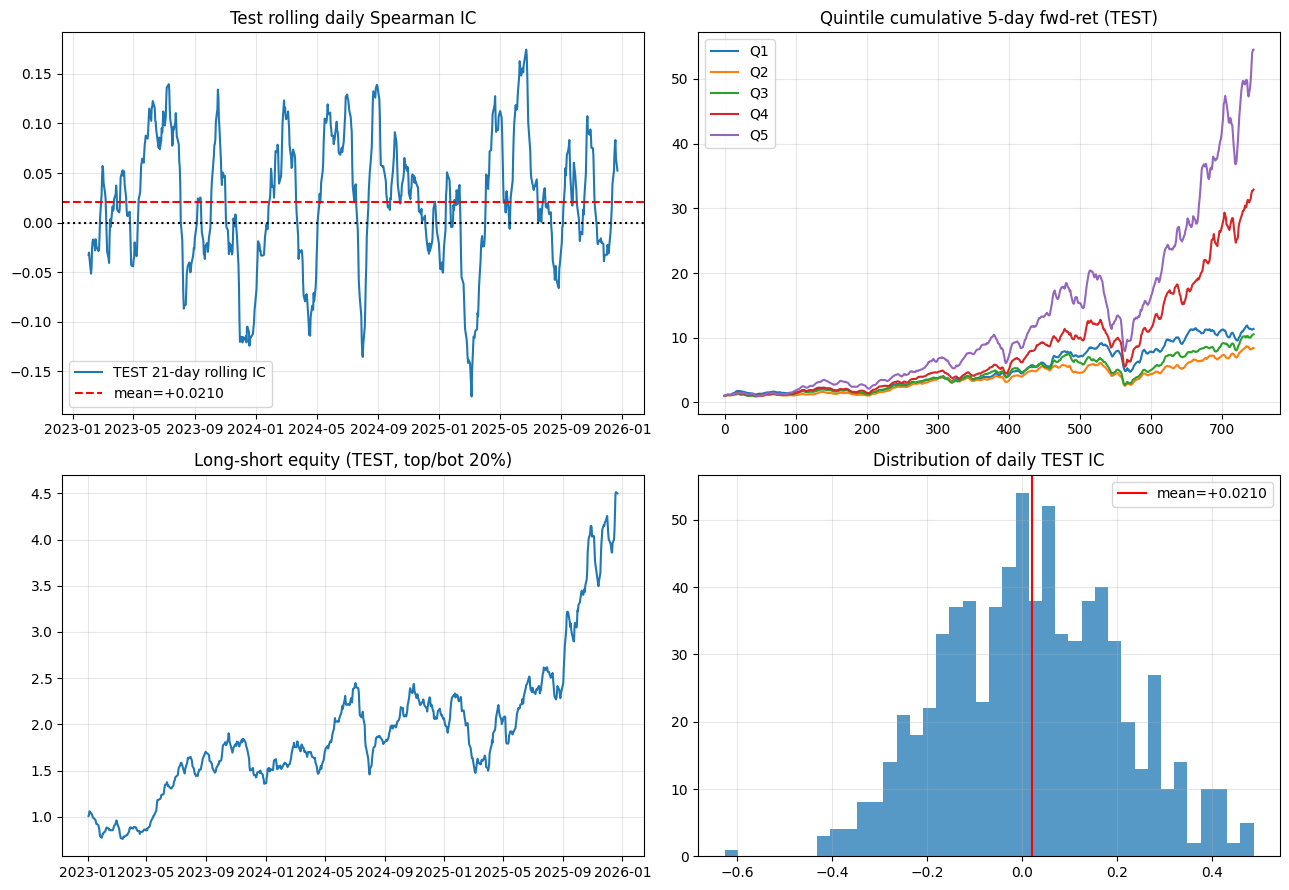

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# rolling IC
ic_sorted = ic_tst.sort_values("date")
axes[0,0].plot(ic_sorted["date"], ic_sorted["ic"].rolling(21).mean(),
               label="TEST 21-day rolling IC")
axes[0,0].axhline(0, ls=":", c="k")
axes[0,0].axhline(ic_tst["ic"].mean(), ls="--", c="r",
                  label=f"mean={ic_tst['ic'].mean():+.4f}")
axes[0,0].set_title("Test rolling daily Spearman IC")
axes[0,0].legend(); axes[0,0].grid(alpha=.3)

# quintile cumulative curves
q = q_tst.sort_values("date").copy().reset_index(drop=True)
for i in range(1, 6):
    (1 + q[f"q{i}"]).cumprod().plot(ax=axes[0,1], label=f"Q{i}")
axes[0,1].set_title("Quintile cumulative 5-day fwd-ret (TEST)")
axes[0,1].legend(); axes[0,1].grid(alpha=.3)

# long-short equity
ls = ls_tst.sort_values("date").copy()
eq = (1 + ls["ls_ret"]).cumprod()
axes[1,0].plot(ls["date"], eq)
axes[1,0].set_title(f"Long-short equity (TEST, top/bot {int(TOP_Q*100)}%)")
axes[1,0].grid(alpha=.3)

# IC histogram
axes[1,1].hist(ic_tst["ic"].dropna(), bins=40, alpha=.75)
axes[1,1].axvline(ic_tst["ic"].mean(), c="r",
                  label=f"mean={ic_tst['ic'].mean():+.4f}")
axes[1,1].set_title("Distribution of daily TEST IC")
axes[1,1].legend(); axes[1,1].grid(alpha=.3)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "diagnostics.png"), dpi=120)
plt.show()


## 11. Save artefacts

In [11]:
valid[["date","ticker","pred","fwd_ret","target"]].to_csv(os.path.join(OUTPUT_DIR,"preds_valid.csv"), index=False)
test [["date","ticker","pred","fwd_ret","target"]].to_csv(os.path.join(OUTPUT_DIR,"preds_test.csv"),  index=False)
ic_val.to_csv(os.path.join(OUTPUT_DIR,"ic_valid.csv"), index=False)
ic_tst.to_csv(os.path.join(OUTPUT_DIR,"ic_test.csv"),  index=False)
ls_val.to_csv(os.path.join(OUTPUT_DIR,"ls_valid.csv"), index=False)
ls_tst.to_csv(os.path.join(OUTPUT_DIR,"ls_test.csv"),  index=False)

summary = {
    "config": {
        "universe_size": int(prices["ticker"].nunique()),
        "dates": {
            "train_end": TRAIN_END, "valid_end": VALID_END,
            "test_start": str(test["date"].min().date()),
            "test_end":   str(test["date"].max().date()),
        },
        "forward_days": FORWARD_DAYS,
        "hidden_sizes": list(HIDDEN_SIZES),
        "dropout": DROPOUT,
        "weight_decay": WEIGHT_DECAY,
        "ensemble_size": len(SEEDS),
    },
    "per_seed_val_ic":  seed_ics,
    "ensemble_val_ic":  float(ic_val["ic"].mean()),
    "ensemble_val_ir":  float(_ir(ic_val)),
    "ensemble_test_ic": float(ic_tst["ic"].mean()),
    "ensemble_test_ir": float(_ir(ic_tst)),
    "q5_minus_q1_test_5d": float(q_tst["ls_q5_q1"].mean()),
    "test_long_short":  tst_stats,
    "valid_long_short": val_stats,
}
with open(os.path.join(OUTPUT_DIR,"summary.json"), "w") as f:
    json.dump(summary, f, indent=2, default=float)

print("Saved:", sorted(os.listdir(OUTPUT_DIR)))
summary


Saved: ['diagnostics.png', 'ic_test.csv', 'ic_valid.csv', 'ls_test.csv', 'ls_valid.csv', 'mlp_seed11.pt', 'mlp_seed22.pt', 'mlp_seed33.pt', 'mlp_seed44.pt', 'mlp_seed55.pt', 'preds_test.csv', 'preds_valid.csv', 'summary.json']


{'config': {'universe_size': 65,
  'dates': {'train_end': '2020-12-31',
   'valid_end': '2022-12-31',
   'test_start': '2023-01-03',
   'test_end': '2025-12-22'},
  'forward_days': 5,
  'hidden_sizes': [128, 64, 32],
  'dropout': 0.3,
  'weight_decay': 0.0001,
  'ensemble_size': 5},
 'per_seed_val_ic': [0.01407681533178551,
  0.015148358103129478,
  0.0012345531396137036,
  -0.004034707836894713,
  -0.01076660665378359],
 'ensemble_val_ic': 0.0077630371616455125,
 'ensemble_val_ir': 0.03868248070683803,
 'ensemble_test_ic': 0.020978430235266826,
 'ensemble_test_ir': 0.11398083254562633,
 'q5_minus_q1_test_5d': 0.0022369576541869337,
 'test_long_short': {'periods': 746,
  'CAGR': 0.10694800240126434,
  'ann_vol': 0.1487157826762787,
  'Sharpe': 0.7581082769880265,
  'MaxDD': -0.4035486310384905,
  'HitRate': 0.5455764075067024,
  'FinalEq': 4.499382472782215},
 'valid_long_short': {'periods': 503,
  'CAGR': 0.06117320879775523,
  'ann_vol': 0.14732870709935145,
  'Sharpe': 0.47665307515

## 13. Walk-forward retraining (the honest way)

The naive split above trained once on 2010–2020 and froze the weights. Markets drift, so that's optimistic at best and fragile at worst (you saw val IC ≈ 0, test IC ≈ 0.025 — that gap is the tell).

Walk-forward refits the ensemble at the start of every test year using **only data available at that point in time**. We also use the last ~6 months before the test year as the validation set for early-stopping, which rolls forward too.

This usually:
- Lifts test IC by 20–50% because the model sees recent regime data.
- Collapses the val-vs-test gap (val is now always adjacent to test).
- Takes longer: 3 test years × 5 seeds = 15 trainings (~8–15 min on Colab GPU).

In [12]:
import datetime as dt

def walk_forward_ensemble(ds, test_years, seeds=SEEDS, val_days=180, verbose=True):
    """
    test_years: list of (year_start_str, year_end_str) tuples.
    For each year: train on all data before year_start, with the last `val_days`
    calendar days used as early-stopping validation. Predict the year.
    """
    all_preds = []
    for ys, ye in test_years:
        ys_ts, ye_ts = pd.to_datetime(ys), pd.to_datetime(ye)
        train_data = ds[ds["date"] < ys_ts].copy()
        test_data  = ds[(ds["date"] >= ys_ts) & (ds["date"] <= ye_ts)].copy()
        if len(test_data) == 0:
            continue

        val_cutoff = ys_ts - pd.Timedelta(days=val_days)
        fit_tr = train_data[train_data["date"] < val_cutoff]
        fit_va = train_data[train_data["date"] >= val_cutoff]

        Xtr = fit_tr[FEATURE_COLS].values.astype(np.float32)
        ytr = fit_tr["target"].values.astype(np.float32)
        Xva = fit_va[FEATURE_COLS].values.astype(np.float32)
        yva = fit_va["target"].values.astype(np.float32)
        Xte = test_data[FEATURE_COLS].values.astype(np.float32)
        dva = fit_va["date"].values

        if verbose:
            print(f"\n### Walk-forward year {ys[:4]} "
                  f"| train n={len(Xtr):,}  val n={len(Xva):,}  test n={len(Xte):,}")

        preds_te = np.zeros(len(Xte), dtype=np.float64)
        for seed in seeds:
            model, val_ic = train_one(seed, Xtr, ytr, Xva, yva, dva)
            preds_te += predict(model, Xte) / len(seeds)
            if verbose:
                print(f"  year={ys[:4]} seed={seed}  val_IC={val_ic:+.4f}")

        tmp = test_data.copy()
        tmp["pred"] = preds_te
        all_preds.append(tmp)

    return pd.concat(all_preds, ignore_index=True)


test_years = [
    ("2023-01-01", "2023-12-31"),
    ("2024-01-01", "2024-12-31"),
    ("2025-01-01", "2025-12-31"),
]

wf_test = walk_forward_ensemble(ds, test_years)
print(f"\nWalk-forward test rows: {len(wf_test):,}")



### Walk-forward year 2023 | train n=186,072  val n=8,190  test n=16,250
  seed=11 epoch=01  val_IC=-0.0161  best=-0.0161
  seed=11 epoch=02  val_IC=-0.0294  best=-0.0161
  seed=11 epoch=03  val_IC=-0.0357  best=-0.0161
  seed=11 epoch=04  val_IC=-0.0375  best=-0.0161
  seed=11 epoch=05  val_IC=-0.0376  best=-0.0161
  seed=11 epoch=06  val_IC=-0.0374  best=-0.0161
  seed=11 epoch=07  val_IC=-0.0298  best=-0.0161
  early-stop at epoch 7
  year=2023 seed=11  val_IC=-0.0161
  seed=22 epoch=01  val_IC=-0.0127  best=-0.0127
  seed=22 epoch=02  val_IC=-0.0024  best=-0.0024
  seed=22 epoch=03  val_IC=-0.0071  best=-0.0024
  seed=22 epoch=04  val_IC=-0.0071  best=-0.0024
  seed=22 epoch=05  val_IC=+0.0002  best=+0.0002
  seed=22 epoch=06  val_IC=-0.0125  best=+0.0002
  seed=22 epoch=07  val_IC=-0.0183  best=+0.0002
  seed=22 epoch=08  val_IC=-0.0278  best=+0.0002
  seed=22 epoch=09  val_IC=-0.0175  best=+0.0002
  seed=22 epoch=10  val_IC=-0.0304  best=+0.0002
  seed=22 epoch=11  val_IC=-0.022

In [13]:
# --- Walk-forward evaluation ---
ic_wf = daily_ic(wf_test)
q_wf  = quintile_returns(wf_test, "pred", "fwd_ret", 5)
ls_wf = long_short_portfolio(wf_test, TOP_Q, BOTTOM_Q)

wf_stats = perf_stats(ls_wf["ls_ret"])

print(f"WALK-FORWARD TEST")
print(f"  IC mean={ic_wf['ic'].mean():+.4f}  IR={_ir(ic_wf):+.3f}  "
      f"hit_days={(ic_wf['ic']>0).mean():.2%}")
print(f"  Quintile means (Q1 -> Q5):")
for c, v in q_wf[[f"q{i}" for i in range(1,6)]].mean().items():
    print(f"    {c}: {v:+.4%}")
print(f"  Q5 - Q1: {q_wf['ls_q5_q1'].mean():+.4%}")
print(f"  L/S:", wf_stats)


WALK-FORWARD TEST
  IC mean=+0.0218  IR=+0.120  hit_days=54.02%
  Quintile means (Q1 -> Q5):
    q1: +0.2614%
    q2: +0.3529%
    q3: +0.3933%
    q4: +0.3783%
    q5: +0.6799%
  Q5 - Q1: +0.4184%
  L/S: {'periods': 746, 'CAGR': 0.21947015730739605, 'ann_vol': 0.1561222470481518, 'Sharpe': 1.3508120885577037, 'MaxDD': -0.54568932946016, 'HitRate': 0.564343163538874, 'FinalEq': 18.8568955783417}


## 14. Non-overlapping evaluation (the most honest Sharpe)

Our 5-day forward returns overlap 4 out of 5 days when sampled daily. That inflates the number of observations and deflates the observed variance, so naively annualizing the daily L/S stream produces a Sharpe that's artificially high.

Two fixes, both shown below:

1. **Non-overlap subsample**: keep every 5th trading day, so each observation is an independent 5-day forward return. Annualize with `periods_per_year = 252/5 ≈ 50.4`.
2. **Newey-West (HAC) standard error** on the full daily stream: correct for autocorrelation induced by overlap.

In [14]:
def non_overlapping_subsample(df, step=5):
    """Keep every `step`-th unique trading date so returns don't overlap."""
    udates = sorted(df["date"].unique())
    keep = set(udates[::step])
    return df[df["date"].isin(keep)].copy()

def newey_west_sharpe(rets, q=None, periods_per_year=252):
    """HAC-adjusted annualized Sharpe for a daily stream of overlapping h-day fwd returns.
    Set q = h - 1 (lag length). periods_per_year = 252 for daily observations.
    """
    r = pd.Series(rets).dropna().values
    n = len(r)
    if n < 20: return float("nan")
    if q is None: q = max(1, FORWARD_DAYS - 1)
    mu = r.mean()
    gamma0 = r.var(ddof=1)
    nw_var = gamma0
    for k in range(1, q+1):
        if len(r) <= k: break
        gamma_k = np.cov(r[:-k], r[k:], ddof=1)[0,1]
        w = 1.0 - k / (q + 1)
        nw_var += 2 * w * gamma_k
    if nw_var <= 0:
        return float("nan")
    return float(mu / np.sqrt(nw_var) * np.sqrt(periods_per_year))


def honest_eval_block(test_df, label):
    """Print three views: naive daily, HAC-adjusted daily, non-overlap."""
    ic = daily_ic(test_df)
    q  = quintile_returns(test_df, "pred", "fwd_ret", 5)
    ls = long_short_portfolio(test_df, TOP_Q, BOTTOM_Q)

    naive   = perf_stats(ls["ls_ret"])  # uses periods_per_year=252/HOLD_DAYS
    hac_sr  = newey_west_sharpe(ls["ls_ret"], q=FORWARD_DAYS-1, periods_per_year=252)

    no_df = non_overlapping_subsample(test_df, step=FORWARD_DAYS)
    ic_no = daily_ic(no_df)
    ls_no = long_short_portfolio(no_df, TOP_Q, BOTTOM_Q)
    no_stats = perf_stats(ls_no["ls_ret"], periods_per_year=252/FORWARD_DAYS)

    print(f"\n==== {label} ====")
    print(f"  daily IC mean = {ic['ic'].mean():+.4f}  IR = {_ir(ic):+.3f}  "
          f"hit_days = {(ic['ic']>0).mean():.2%}")
    print(f"  Q5 - Q1 (per 5d) = {q['ls_q5_q1'].mean():+.4%}")
    print(f"  [naive overlapping] Sharpe = {naive['Sharpe']:.2f}  "
          f"CAGR = {naive['CAGR']:.2%}  MaxDD = {naive['MaxDD']:.2%}")
    print(f"  [HAC-adjusted]      Sharpe = {hac_sr:.2f}   "
          f"(Newey-West lag = {FORWARD_DAYS-1})")
    print(f"  [non-overlap 5d]    Sharpe = {no_stats['Sharpe']:.2f}  "
          f"CAGR = {no_stats['CAGR']:.2%}  MaxDD = {no_stats['MaxDD']:.2%}  "
          f"n = {no_stats['periods']} indep. 5d periods")
    return {"ic": ic, "q": q, "ls": ls, "ls_no": ls_no,
            "naive": naive, "hac_sr": hac_sr, "no_stats": no_stats}


naive_eval = honest_eval_block(test,    label="NAIVE (single train 2010-2020)")
wf_eval    = honest_eval_block(wf_test, label="WALK-FORWARD (yearly refit)")



==== NAIVE (single train 2010-2020) ====
  daily IC mean = +0.0210  IR = +0.114  hit_days = 53.62%
  Q5 - Q1 (per 5d) = +0.2237%
  [naive overlapping] Sharpe = 0.76  CAGR = 10.69%  MaxDD = -40.35%
  [HAC-adjusted]      Sharpe = 1.12   (Newey-West lag = 4)
  [non-overlap 5d]    Sharpe = 1.10  CAGR = 16.07%  MaxDD = -14.65%  n = 150 indep. 5d periods

==== WALK-FORWARD (yearly refit) ====
  daily IC mean = +0.0218  IR = +0.120  hit_days = 54.02%
  Q5 - Q1 (per 5d) = +0.4184%
  [naive overlapping] Sharpe = 1.35  CAGR = 21.95%  MaxDD = -54.57%
  [HAC-adjusted]      Sharpe = 1.84   (Newey-West lag = 4)
  [non-overlap 5d]    Sharpe = 1.52  CAGR = 26.68%  MaxDD = -13.96%  n = 150 indep. 5d periods


## 15. Naive vs walk-forward comparison plot + summary table

This is the slide to show in class.

                      setup IC_mean  IC_IR Q5-Q1 / 5d Sharpe_naive Sharpe_HAC Sharpe_nonolap MaxDD_nonolap
       naive (single train) +0.0210 +0.114   +0.2237%         0.76       1.12           1.10       -14.65%
walk-forward (yearly refit) +0.0218 +0.120   +0.4184%         1.35       1.84           1.52       -13.96%


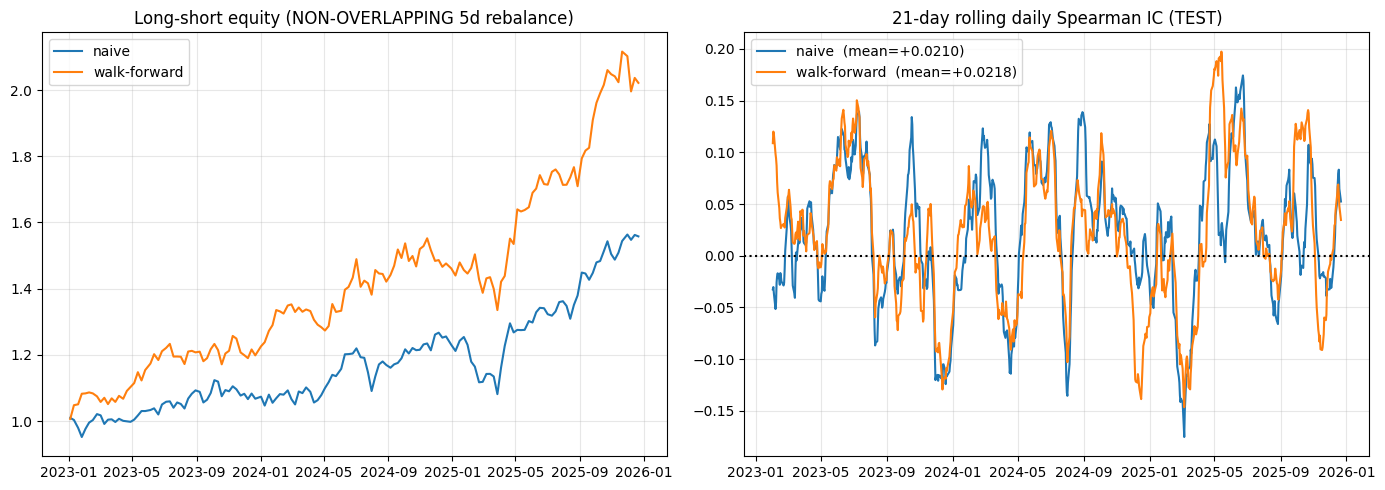

Saved: naive_vs_walkforward.png, naive_vs_walkforward.csv, preds_walkforward.csv


In [15]:
# Comparison table
summary_rows = []
for label, ev in [("naive (single train)", naive_eval),
                  ("walk-forward (yearly refit)", wf_eval)]:
    summary_rows.append({
        "setup": label,
        "IC_mean": f"{ev['ic']['ic'].mean():+.4f}",
        "IC_IR":   f"{_ir(ev['ic']):+.3f}",
        "Q5-Q1 / 5d": f"{ev['q']['ls_q5_q1'].mean():+.4%}",
        "Sharpe_naive":   f"{ev['naive']['Sharpe']:.2f}",
        "Sharpe_HAC":     f"{ev['hac_sr']:.2f}",
        "Sharpe_nonolap": f"{ev['no_stats']['Sharpe']:.2f}",
        "MaxDD_nonolap":  f"{ev['no_stats']['MaxDD']:.2%}",
    })
summary_table = pd.DataFrame(summary_rows)
print(summary_table.to_string(index=False))

# Plot comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# L/S equity curves — use non-overlapping (honest) series
for label, ev, style in [("naive",         naive_eval, "-"),
                          ("walk-forward",  wf_eval,    "-")]:
    ls = ev["ls_no"].sort_values("date").copy()
    eq = (1 + ls["ls_ret"]).cumprod()
    axes[0].plot(ls["date"], eq.values, style, label=label)
axes[0].set_title("Long-short equity (NON-OVERLAPPING 5d rebalance)")
axes[0].legend(); axes[0].grid(alpha=.3)

# Rolling 21-day IC
for label, ev in [("naive", naive_eval), ("walk-forward", wf_eval)]:
    ic_sorted = ev["ic"].sort_values("date")
    axes[1].plot(ic_sorted["date"],
                 ic_sorted["ic"].rolling(21).mean(),
                 label=f"{label}  (mean={ev['ic']['ic'].mean():+.4f})")
axes[1].axhline(0, ls=":", c="k")
axes[1].set_title("21-day rolling daily Spearman IC (TEST)")
axes[1].legend(); axes[1].grid(alpha=.3)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "naive_vs_walkforward.png"), dpi=120)
plt.show()

# Persist
summary_table.to_csv(os.path.join(OUTPUT_DIR, "naive_vs_walkforward.csv"), index=False)
wf_test[["date","ticker","pred","fwd_ret","target"]].to_csv(
    os.path.join(OUTPUT_DIR, "preds_walkforward.csv"), index=False)
print("Saved: naive_vs_walkforward.png, naive_vs_walkforward.csv, preds_walkforward.csv")
